In [ ]:
## Comparison the Three TC Mozambique 

In [1]:
from climada_petals.hazard import TCForecast
import logging
import datetime
import os
import numpy as np
import geopandas as gpd
import pickle

In [2]:
### impacts calculated
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/imph2_impp1.pkl', 'rb') as file:
    imph2_impp1_IDAI = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/ed2_impp1.pkl', 'rb') as file:
    ed2_impp1_IDAI = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/impp1_disrupted.pkl', 'rb') as file:
    impp1_disrupted_IDAI = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/rd2_disrupted_impp1.pkl', 'rb') as file:
    rd2_disrupted_impp1_IDAI = pickle.load(file)

In [3]:
### impacts calculated
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/imph2_impp1.pkl', 'rb') as file:
    imph2_impp1_FREDDY = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/ed2_impp1.pkl', 'rb') as file:
    ed2_impp1_FREDDY = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp1_disrupted.pkl', 'rb') as file:
    impp1_disrupted_FREDDY = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/rd2_disrupted_impp1.pkl', 'rb') as file:
    rd2_disrupted_impp1_FREDDY = pickle.load(file)

In [4]:
### impacts calculated
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/imph2_impp1.pkl', 'rb') as file:
    imph2_impp1_KENNETH = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/ed2_impp1.pkl', 'rb') as file:
    ed2_impp1_KENNETH = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/impp1_disrupted.pkl', 'rb') as file:
    impp1_disrupted_KENNETH = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/rd2_disrupted_impp1.pkl', 'rb') as file:
    rd2_disrupted_impp1_KENNETH = pickle.load(file)

In [5]:
from climada.entity.exposures.base import Exposures
gdf_worldpop_MOZ = Exposures.from_raster ('/cluster/work/climate/gespejo/data/infrastructure/population/moz_ppp_2020_1km_Aggregated_UNadj.tif')

In [6]:
gdf_worldpop_MOZ.set_geometry_points()

In [7]:
###SUBNATIONAL DIVISION 
import geopandas as gpd
geofile_MOZ = '/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ/gadm41_MOZ_shp/gadm41_MOZ_1.shp'
gadm_MOZ = gpd.read_file(geofile_MOZ)

In [8]:
gdf_worldpop_MOZ.gdf

,longitude,latitude,value,geometry
0,30.219583,-10.471250,0.0,POINT (30.21958 -10.47125)
1,30.227917,-10.471250,0.0,POINT (30.22792 -10.47125)
2,30.236250,-10.471250,0.0,POINT (30.23625 -10.47125)
3,30.244583,-10.471250,0.0,POINT (30.24458 -10.47125)
4,30.252917,-10.471250,0.0,POINT (30.25292 -10.47125)
...,...,...,...,...
2509195,40.802917,-26.862916,0.0,POINT (40.80292 -26.86292)
2509196,40.811250,-26.862916,0.0,POINT (40.81125 -26.86292)
2509197,40.819583,-26.862916,0.0,POINT (40.81958 -26.86292)
2509198,40.827917,-26.862916,0.0,POINT (40.82792 -26.86292)


In [9]:
import geopandas as gpd

# Make sure both GeoDataFrames are in the same CRS
gdf_worldpop_MOZ = gdf_worldpop_MOZ.gdf.to_crs(gadm_MOZ.crs)

# Spatial join: assign each population point a province name from GADM
gdf_worldpop_MOZ = gpd.sjoin(
    gdf_worldpop_MOZ,
    gadm_MOZ[['NAME_1', 'geometry']],  # keep only needed columns
    how='left',
    predicate='within'  # or 'within' for point-in-polygon
)

In [10]:
gdf_worldpop_MOZ 

,longitude,latitude,value,geometry,index_right,NAME_1
0,30.219583,-10.471250,0.0,POINT (30.21958 -10.47125),NaN,NaN
1,30.227917,-10.471250,0.0,POINT (30.22792 -10.47125),NaN,NaN
2,30.236250,-10.471250,0.0,POINT (30.23625 -10.47125),NaN,NaN
3,30.244583,-10.471250,0.0,POINT (30.24458 -10.47125),NaN,NaN
4,30.252917,-10.471250,0.0,POINT (30.25292 -10.47125),NaN,NaN
...,...,...,...,...,...,...
2509195,40.802917,-26.862916,0.0,POINT (40.80292 -26.86292),NaN,NaN
2509196,40.811250,-26.862916,0.0,POINT (40.81125 -26.86292),NaN,NaN
2509197,40.819583,-26.862916,0.0,POINT (40.81958 -26.86292),NaN,NaN
2509198,40.827917,-26.862916,0.0,POINT (40.82792 -26.86292),NaN,NaN


In [11]:
pop_per_province = gdf_worldpop_MOZ.dropna(subset=['NAME_1']).groupby('NAME_1')['value'].sum()

In [12]:
## Comparing relatives values of affectation 

In [13]:
### FREDDY TROPICAL CYCLONE 
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter, MaxNLocator

# Define lead times and province colors
lead_times = ['5 days', '4 days', '3 days', '2 days', '1 day']

# Initialize data structures
leadtime_province_h2 = {}
leadtime_province_ed2 = {}
leadtime_province_p1 = {}
leadtime_province_rd2 = {}

# Aggregate data per lead time and province
for lt in lead_times:
    df_h2_FREDDY = imph2_impp1_FREDDY[lt]
    leadtime_province_h2[lt] = df_h2_FREDDY.groupby('NAME_1')['pp_affected'].sum()

    df_ed2_FREDDY = ed2_impp1_FREDDY[lt]
    leadtime_province_ed2[lt] = df_ed2_FREDDY.groupby('NAME_1')['pp_affected'].sum()

    df_p1_FREDDY = impp1_disrupted_FREDDY[lt]
    leadtime_province_p1[lt] = df_p1_FREDDY.groupby('NAME_1')['people'].sum()

    df_rd2_FREDDY = rd2_disrupted_impp1_FREDDY[lt]
    leadtime_province_rd2[lt] = df_rd2_FREDDY.groupby('NAME_1')['pp_affected'].sum()

# Convert to DataFrames and fill missing data
df_h2_FREDDY = pd.DataFrame(leadtime_province_h2).T.fillna(0)
df_ed2_FREDDY = pd.DataFrame(leadtime_province_ed2).T.fillna(0)
df_p1_FREDDY = pd.DataFrame(leadtime_province_p1).T.fillna(0)
df_rd2_FREDDY = pd.DataFrame(leadtime_province_rd2).T.fillna(0)

# Add total column per day for each impact type
df_h2_FREDDY["Total"] = df_h2_FREDDY.sum(axis=1)
df_ed2_FREDDY["Total"] = df_ed2_FREDDY.sum(axis=1)
df_p1_FREDDY["Total"] = df_p1_FREDDY.sum(axis=1)
df_rd2_FREDDY["Total"] = df_rd2_FREDDY.sum(axis=1)

In [14]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter, MaxNLocator

# Define lead times and province colors
lead_times = ['4 days', '3 days', '2 days', '1 day']

# Initialize data structures
leadtime_province_h2 = {}
leadtime_province_ed2 = {}
leadtime_province_p1 = {}
leadtime_province_rd2 = {}

# Aggregate data per lead time and province
for lt in lead_times:
    df_h2_IDAI= imph2_impp1_IDAI[lt]
    leadtime_province_h2[lt] = df_h2_IDAI.groupby('NAME_1')['pp_affected'].sum()

    df_ed2_IDAI = ed2_impp1_IDAI[lt]
    leadtime_province_ed2[lt] = df_ed2_IDAI.groupby('NAME_1')['pp_affected'].sum()

    df_p1_IDAI = impp1_disrupted_IDAI[lt]
    leadtime_province_p1[lt] = df_p1_IDAI.groupby('NAME_1')['people'].sum()

    df_rd2_IDAI = rd2_disrupted_impp1_IDAI[lt]
    leadtime_province_rd2[lt] = df_rd2_IDAI.groupby('NAME_1')['pp_affected'].sum()

# Convert to DataFrames and fill missing data
df_h2_IDAI = pd.DataFrame(leadtime_province_h2).T.fillna(0)
df_ed2_IDAI = pd.DataFrame(leadtime_province_ed2).T.fillna(0)
df_p1_IDAI = pd.DataFrame(leadtime_province_p1).T.fillna(0)
df_rd2_IDAI = pd.DataFrame(leadtime_province_rd2).T.fillna(0)

# Add total column per day for each impact type
df_h2_IDAI["Total"] = df_h2_IDAI.sum(axis=1)
df_ed2_IDAI["Total"] = df_ed2_IDAI.sum(axis=1)
df_p1_IDAI["Total"] = df_p1_IDAI.sum(axis=1)
df_rd2_IDAI["Total"] = df_rd2_IDAI.sum(axis=1)

In [15]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter, MaxNLocator

# Define lead times and province colors
lead_times = ['2 days', '1 day']

# Initialize data structures
leadtime_province_h2 = {}
leadtime_province_ed2 = {}
leadtime_province_p1 = {}
leadtime_province_rd2 = {}

# Aggregate data per lead time and province
for lt in lead_times:
    df_h2_KENNETH = imph2_impp1_KENNETH[lt]
    leadtime_province_h2[lt] = df_h2_KENNETH.groupby('NAME_1')['pp_affected'].sum()

    df_ed2_KENNETH = ed2_impp1_KENNETH[lt]
    leadtime_province_ed2[lt] = df_ed2_KENNETH.groupby('NAME_1')['pp_affected'].sum()

    df_p1_KENNETH = impp1_disrupted_KENNETH[lt]
    leadtime_province_p1[lt] = df_p1_KENNETH.groupby('NAME_1')['people'].sum()

    df_rd2_KENNETH = rd2_disrupted_impp1_KENNETH[lt]
    leadtime_province_rd2[lt] = df_rd2_KENNETH.groupby('NAME_1')['pp_affected'].sum()

# Convert to DataFrames and fill missing data
df_h2_KENNETH = pd.DataFrame(leadtime_province_h2).T.fillna(0)
df_ed2_KENNETH = pd.DataFrame(leadtime_province_ed2).T.fillna(0)
df_p1_KENNETH = pd.DataFrame(leadtime_province_p1).T.fillna(0)
df_rd2_KENNETH = pd.DataFrame(leadtime_province_rd2).T.fillna(0)

# Add total column per day for each impact type
df_h2_KENNETH["Total"] = df_h2_KENNETH.sum(axis=1)
df_ed2_KENNETH["Total"] = df_ed2_KENNETH.sum(axis=1)
df_p1_KENNETH["Total"] = df_p1_KENNETH.sum(axis=1)
df_rd2_KENNETH["Total"] = df_rd2_KENNETH.sum(axis=1)

In [16]:
df_h2_IDAI

NAME_1,Inhambane,Manica,Sofala,Zambezia,Total
4 days,0.0,0.0,34414.0,1280.0,35694.0
3 days,0.0,0.0,34063.0,93.0,34156.0
2 days,0.0,264.0,34312.0,1306.0,35882.0
1 day,0.0,121.0,38659.0,0.0,38780.0


In [17]:
df_h2_FREDDY

NAME_1,Nampula,Sofala,Zambezia,Total
5 days,1344.0,0.0,32238.0,33582.0
4 days,0.0,0.0,23379.0,23379.0
3 days,0.0,0.0,1695.0,1695.0
2 days,0.0,0.0,24283.0,24283.0
1 day,0.0,1676.0,23312.0,24988.0


In [18]:
df_h2_KENNETH 

NAME_1,Cabo Delgado,Total
2 days,0,0
1 day,688,688


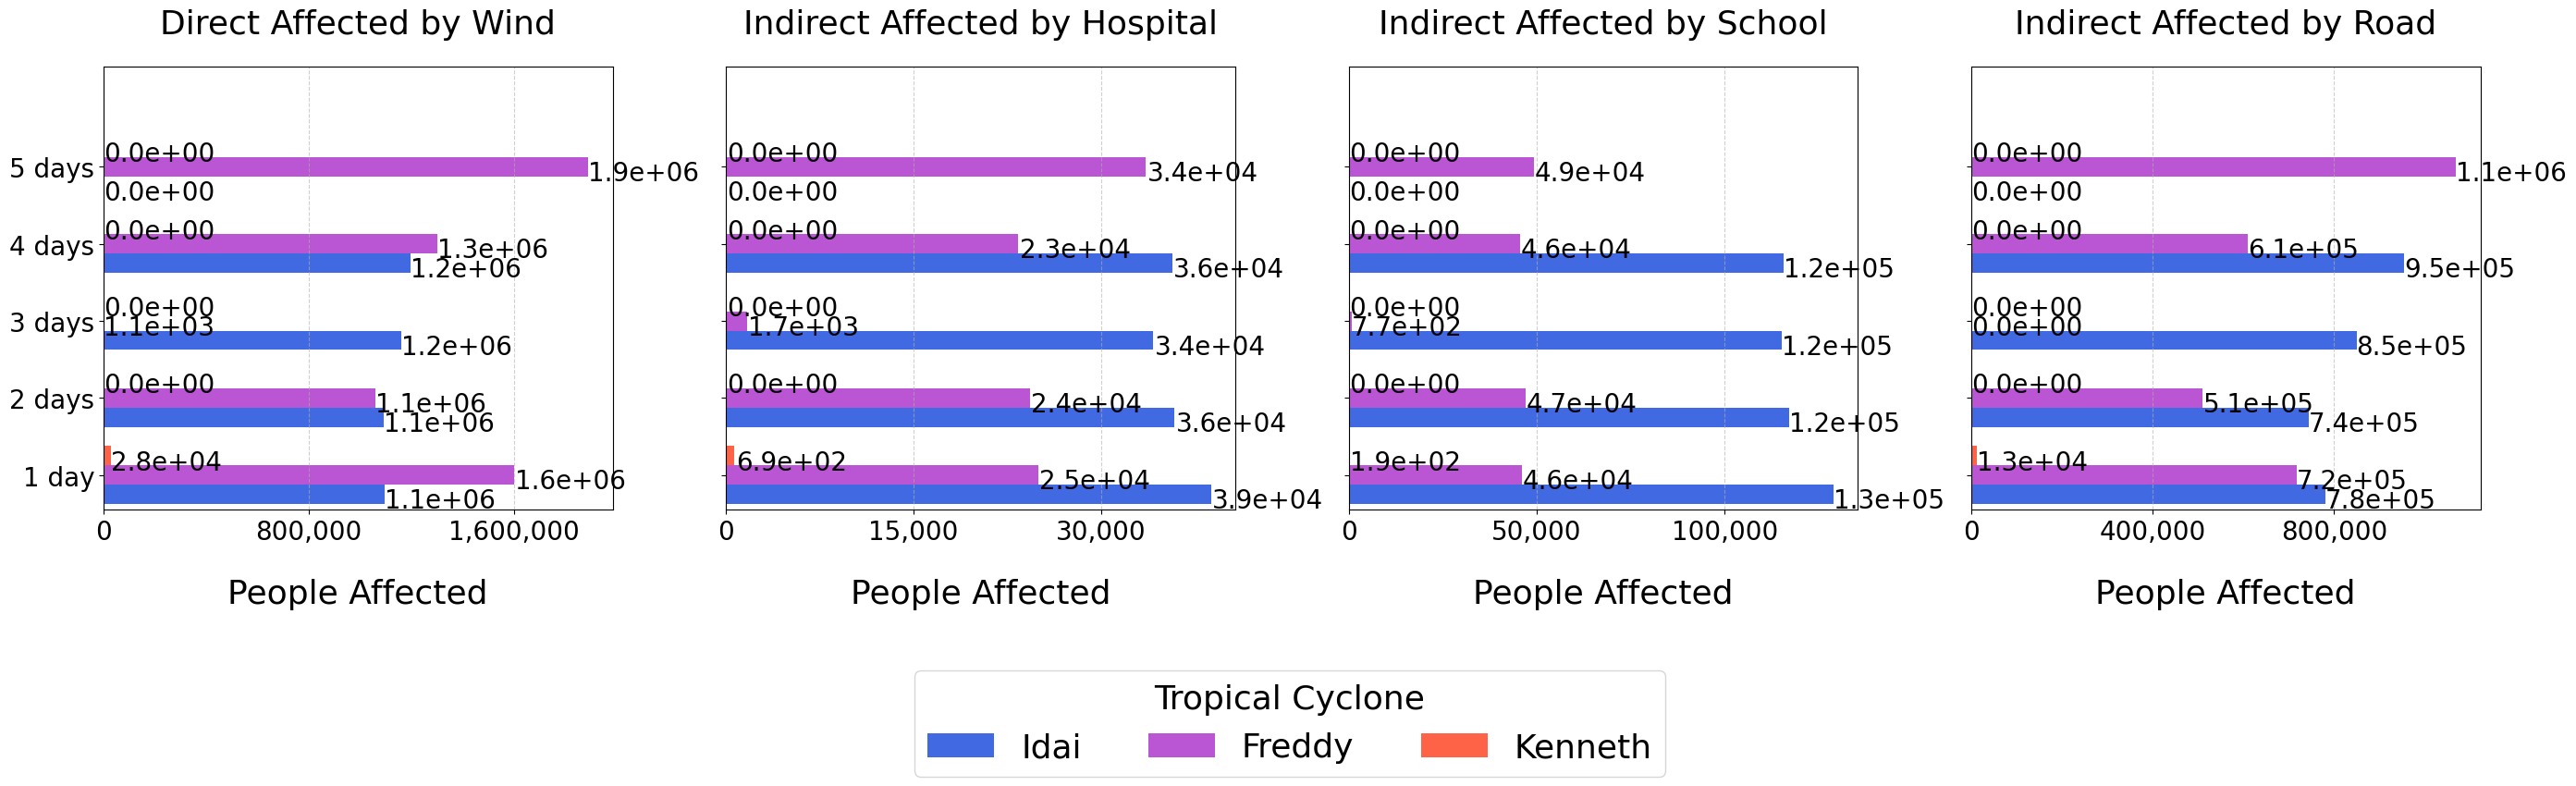

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import StrMethodFormatter, MaxNLocator

# Define cyclone colors
colors = {
    "Idai": "royalblue",
    "Freddy": "mediumorchid",
    "Kenneth": "tomato"
}

# Helper function to generate the comparison plot
def plot_four_comparisons(dfs, titles):
    fig, axs = plt.subplots(ncols=4, figsize=(28, 8), sharey=True)
    bar_width = 0.25

    for idx, (df_dict, title) in enumerate(zip(dfs, titles)):
        ax = axs[idx]
        df_comparison = pd.DataFrame(df_dict).fillna(0)
        y = np.arange(len(df_comparison.index))

        for i, (cyclone, color) in enumerate(colors.items()):
            ax.barh(y + i * bar_width, df_comparison[cyclone], height=bar_width, label=cyclone, color=color)

            for j, val in enumerate(df_comparison[cyclone]):
                # Format bar-end labels in scientific notation
                label = f"{val:.1e}"
                ax.text(val + 100, y[j] + i * bar_width - 0.08, label, va='center', fontsize=20)

        ax.set_yticks(y + bar_width)
        ax.set_yticklabels(df_comparison.index, fontsize=20)
        ax.set_ylim(-0.2, len(y) - 0.2 + bar_width * len(colors))
        ax.set_xlabel("People Affected", fontsize=26, labelpad=26)
        ax.set_title(title, fontsize=26, pad=26)
        ax.tick_params(axis='x', labelsize=20)
        ax.grid(axis='x', linestyle='--', alpha=0.6)

        # X-axis with commas and only 3 ticks
        ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))

    # Shared legend
    handles, labels = axs[0].get_legend_handles_labels()
    fig.legend(
        handles, labels,
        title="Tropical Cyclone",
        fontsize=26,
        title_fontsize=26,
        loc='lower center',
        ncol=3,
        bbox_to_anchor=(0.5, -0.08)
    )
    plt.tight_layout(rect=[0, 0.15, 1, 1])
    fig.savefig("/cluster/home/gespejo/MOZ_struc_plots_Freddy/TCs_comparison.png", dpi=300, bbox_inches='tight')
    plt.show()

# Define the comparison dictionaries and titles
hospital_comparison = {
    "Idai": df_h2_IDAI["Total"],
    "Freddy": df_h2_FREDDY["Total"],
    "Kenneth": df_h2_KENNETH["Total"]
}

school_comparison = {
    "Idai": df_ed2_IDAI["Total"],
    "Freddy": df_ed2_FREDDY["Total"],
    "Kenneth": df_ed2_KENNETH["Total"]
}

road_comparison = {
    "Idai": df_rd2_IDAI["Total"],
    "Freddy": df_rd2_FREDDY["Total"],
    "Kenneth": df_rd2_KENNETH["Total"]
}

wind_comparison = {
    "Idai": df_p1_IDAI["Total"],
    "Freddy": df_p1_FREDDY["Total"],
    "Kenneth": df_p1_KENNETH["Total"]
}

# Call the function with all four comparisons
plot_four_comparisons(
    [wind_comparison, hospital_comparison, school_comparison, road_comparison],
    ["Direct Affected by Wind", "Indirect Affected by Hospital", "Indirect Affected by School", "Indirect Affected by Road"])